In [24]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
from src.data.data import build_auctions
from src.features.build_features import build_features
from src.models.ridge import prepare_auctions, walk_forward_ridge

import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

from src.evaluation import Evaluator
from src.models.baseline import PreviousKnownAuctionBaseline
from src.models.ridge import to_contract

auctions_all = prepare_auctions(build_auctions(product="mFRR"), ("daily", "weekly"))
features_all = build_features(auctions_all)
features_all.groupby(["freq", "direction"]).size()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


freq    direction
daily   downwards    17040
        upwards      17034
weekly  downwards      410
        upwards        410
dtype: int64

In [25]:
preds_all = walk_forward_ridge(features_all, start_test="2024-01-01", end_test="2024-12-31")
print(len(preds_all), "auctions predicted")

4120 auctions predicted


In [ ]:
DEV_START, DEV_END = "2024-01-01", "2025-01-01"
gc = auctions_all["gc"]
in_dev = (gc >= pd.Timestamp(DEV_START, tz="UTC")) & (gc < pd.Timestamp(DEV_END, tz="UTC"))

baseline = PreviousKnownAuctionBaseline().fit(auctions_all)
preds_baseline = baseline.predict(auctions_all[in_dev])

preds_ridge = to_contract(preds_all)

# os dois avaliados pelo mesmo Evaluator, só em 2024
evaluator = Evaluator(actuals=auctions_all, start_test=DEV_START, end_test=DEV_END)
comparison = evaluator.evaluate_many({"baseline": preds_baseline, "ridge_lags3": preds_ridge})
comparison.pivot_table(index=["freq", "direction"], columns="model", values="mae").round(3)

model             baseline  ridge_lags3
freq   direction                       
daily  downwards     0.253        0.292
       upwards       0.293        0.282
weekly downwards     0.126        0.128
       upwards       0.046        0.053

In [ ]:
scored = preds_all[preds_all["y"].notna()]        
mae_all = pd.DataFrame({
    model: (scored[f"pred_{model}"] - scored["y"]).abs().groupby([scored["freq"], scored["direction"]]).mean()
    for model in ["baseline", "ridge"]
})
mae_all["n"] = scored.groupby(["freq", "direction"]).size()
mae_all.round(3)

baseline  ridge    n
freq   direction                      
daily  downwards     0.253  0.292  192
       upwards       0.293  0.282  348
weekly downwards     0.126  0.128   53
       upwards       0.046  0.053   53

In [28]:
daily = scored[scored["freq"] == "daily"]
by_block = pd.DataFrame({
    model: (daily[f"pred_{model}"] - daily["y"]).abs().groupby([daily["direction"], daily["series"]]).mean()
    for model in ["baseline", "ridge"]
}).round(3)
by_block

baseline  ridge
direction series                                
downwards daily|downwards|00_04     0.211  0.239
          daily|downwards|04_08     0.228  0.271
          daily|downwards|08_12     0.311  0.343
          daily|downwards|12_16     0.247  0.288
          daily|downwards|16_20     0.271  0.317
          daily|downwards|20_24     0.247  0.294
upwards   daily|upwards|00_04       0.241  0.267
          daily|upwards|04_08       0.302  0.281
          daily|upwards|08_12       0.336  0.313
          daily|upwards|12_16       0.288  0.260
          daily|upwards|16_20       0.324  0.326
          daily|upwards|20_24       0.264  0.247

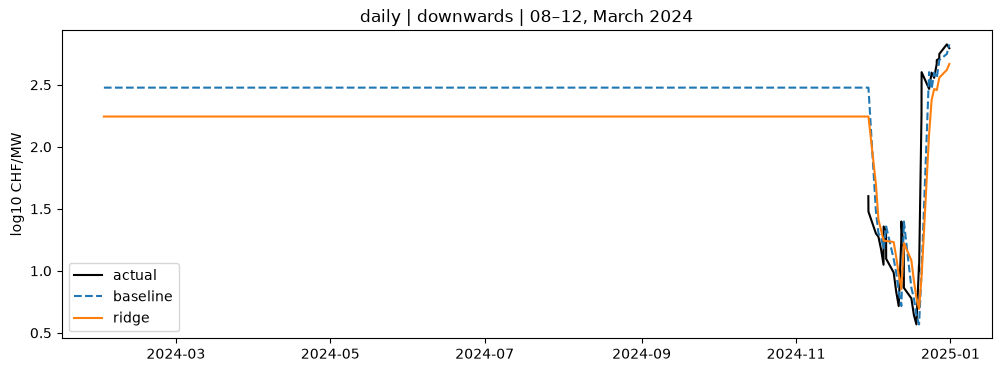

In [32]:
s = preds_all[(preds_all["series"] == "daily|downwards|08_12") & (preds_all["gc"] < pd.Timestamp("2025-01-01", tz="UTC"))
              & (preds_all["gc"] >= pd.Timestamp("2024-02-01", tz="UTC"))]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s["gc"], s["y"], "k-", label="actual")
ax.plot(s["gc"], s["pred_baseline"], "--", label="baseline")
ax.plot(s["gc"], s["pred_ridge"], "-", label="ridge")
ax.set_ylabel("log10 CHF/MW")
ax.set_title("daily | downwards | 08–12, March 2024")
ax.legend()
plt.show()

In [30]:
FEATURES = ["lag1", "lag2", "lag3"]
tr = features_all[features_all["avail"] < "2024-01-01"].dropna(subset=FEATURES + ["y"])

rows = []
for (freq, direction), d in tr.groupby(["freq", "direction"]):
    m = Ridge(alpha=1.0).fit(d[FEATURES], d["y"])
    rows.append({"freq": freq, "direction": direction, "n_train": len(d),
                 **dict(zip(FEATURES, m.coef_)), "sum_coef": m.coef_.sum(), "intercept": m.intercept_})

pd.DataFrame(rows).round(3)

,freq,direction,n_train,lag1,lag2,lag3,sum_coef,intercept
0,daily,downwards,9810,0.458,0.272,0.192,0.922,0.109
1,daily,upwards,10195,0.469,0.112,0.227,0.808,0.132
2,weekly,downwards,258,0.786,0.197,-0.008,0.974,0.082
3,weekly,upwards,258,0.804,0.092,0.078,0.973,0.070
